# Análisis y visualización de noticias de La República

Este notebook analiza el CSV preparado en `01_preprocesamiento.ipynb`. Cada gráfica y tabla se genera con código visible y resultados verificables. Las proporciones son descriptivas de la muestra recopilada.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / 'data' / 'noticias_larepublica_final.csv').exists():
    RAIZ = RAIZ.parent
if not (RAIZ / 'data' / 'noticias_larepublica_final.csv').exists():
    raise FileNotFoundError('Ejecute primero 01_preprocesamiento.ipynb para crear el CSV final.')
FIGS = RAIZ / 'figures'
FIGS.mkdir(parents=True, exist_ok=True)
AZUL = '#16324f'
TURQUESA = '#147b80'
GRIS = '#737e8b'
df = pd.read_csv(RAIZ / 'data' / 'noticias_larepublica_final.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(1116, 18)


,tag,titulo,longitud_titulo,url,autor,hora,fecha,seccion,anio,mes,anio_mes,dia_semana,hora_num,franja_horaria,fin_de_semana,palabras_titulo,contiene_pregunta,contiene_cifra
0,JNE,JEE Lima Centro archiva proceso contra Rafael ...,82,https://larepublica.pe/politica/2026/09/22/jee...,Jazmín Bianchi,11:34,2026-09-22,Política,2026,9,2026-09,Martes,11,Mañana (06-11),False,12,False,False
1,Animales,En 1871 dejaron cinco vacas en una isla desier...,126,https://larepublica.pe/ciencia/2026/09/21/en-1...,Renzo Loza,11:33,2026-09-22,Ciencia,2026,9,2026-09,Martes,11,Mañana (06-11),False,22,False,True
2,Luiz Inácio Lula da Silva,Lula denuncia en la ONU la injerencia externa ...,126,https://larepublica.pe/mundo/2026/09/22/lula-d...,Daniela Magallanes,11:33,2026-09-22,Mundo,2026,9,2026-09,Martes,11,Mañana (06-11),False,22,False,False
3,Sicariato,Crimen de Susy Aponte: PNP presenta evidencias...,111,https://larepublica.pe/sociedad/2026/09/22/cri...,Aarón Torres,11:32,2026-09-22,Sociedad,2026,9,2026-09,Martes,11,Mañana (06-11),False,18,False,True
4,Ayacucho,Gobierno Regional Ayacucho convoca a empresa p...,102,https://larepublica.pe/publirreportajes/2026/0...,Redacción LR,11:29,2026-09-22,Publirreportajes,2026,9,2026-09,Martes,11,Mañana (06-11),False,14,False,False


In [2]:
def estilo():
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':14,'axes.labelsize':10,'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','axes.spines.top':False,'axes.spines.right':False,'grid.alpha':0.18})


def guardar(nombre):
    plt.savefig(FIGS/nombre,dpi=200,bbox_inches='tight',facecolor='white')
    plt.show()
    plt.close()

estilo()
grupo = df.seccion.value_counts()

## 1. Distribución por sección

Las frecuencias representan el peso de cada categoría en las noticias recopiladas. No deben interpretarse como una estimación de la distribución total del diario.

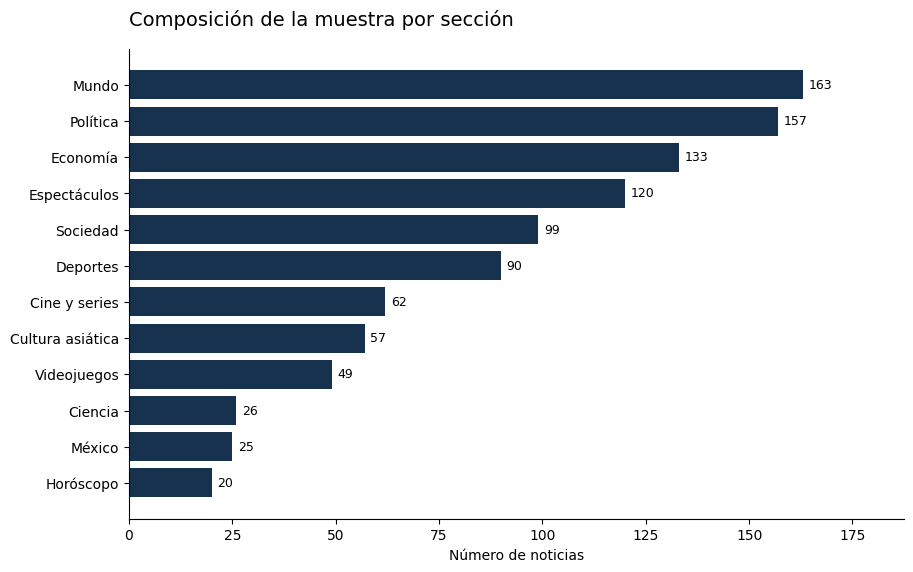

In [3]:
top=grupo.head(12).sort_values()
plt.figure(figsize=(10,6.1))
ax=plt.gca()
bars=ax.barh(top.index,top.values,color=AZUL)
ax.bar_label(bars,padding=4,fontsize=9)
ax.set_xlim(0,top.max()*1.15);ax.set_xlabel('Número de noticias');ax.set_title('Composición de la muestra por sección',loc='left',pad=17)
guardar('01_secciones.png')

## 2. Autores con mayor presencia en la muestra

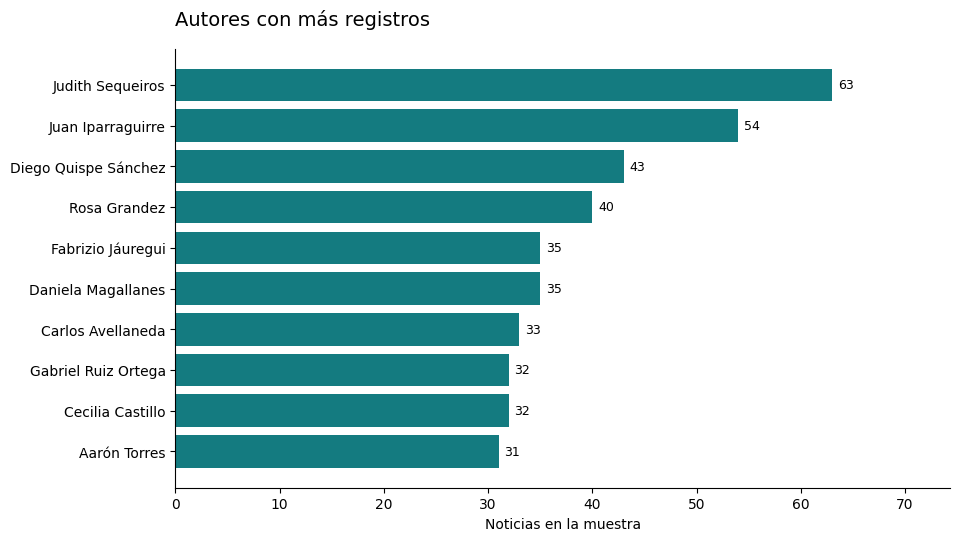

In [4]:
top=df.autor.value_counts().head(10).sort_values()
plt.figure(figsize=(10,5.7));ax=plt.gca();bars=ax.barh(top.index,top.values,color=TURQUESA);ax.bar_label(bars,padding=4,fontsize=9)
ax.set_xlim(0,top.max()*1.18);ax.set_xlabel('Noticias en la muestra');ax.set_title('Autores con más registros',loc='left',pad=17)
guardar('02_autores.png')

## 3. Horarios registrados

La concentración por hora depende de los registros que fueron recopilados.

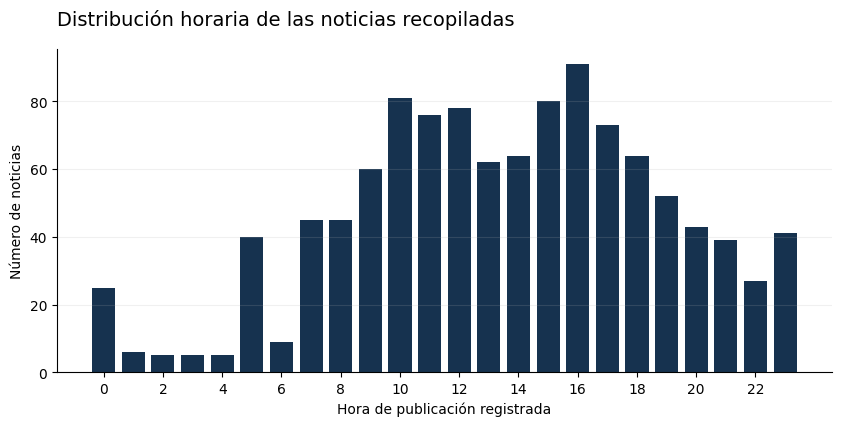

In [5]:
horas=df.hora_num.value_counts().reindex(range(24),fill_value=0)
plt.figure(figsize=(10,4.2));ax=plt.gca();ax.bar(horas.index,horas.values,color=AZUL,width=.78)
ax.set_xticks(list(range(0,24,2)));ax.set_xlabel('Hora de publicación registrada');ax.set_ylabel('Número de noticias')
ax.set_title('Distribución horaria de las noticias recopiladas',loc='left',pad=17);ax.grid(axis='y')
guardar('03_horas.png')

## 4. Distribución de la longitud de titulares

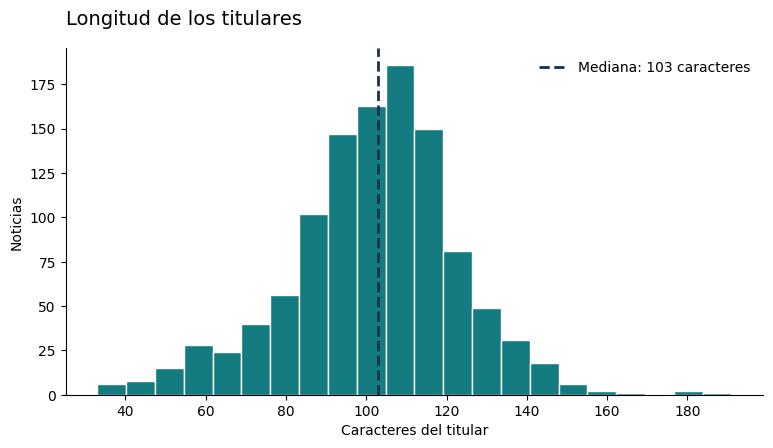

In [6]:
plt.figure(figsize=(9,4.5));ax=plt.gca();ax.hist(df.longitud_titulo,bins=22,color=TURQUESA,edgecolor='white')
ax.axvline(df.longitud_titulo.median(),color=AZUL,linestyle='--',linewidth=2,label=f'Mediana: {df.longitud_titulo.median():.0f} caracteres')
ax.set_xlabel('Caracteres del titular');ax.set_ylabel('Noticias');ax.legend(frameon=False)
ax.set_title('Longitud de los titulares',loc='left',pad=17)
guardar('04_longitud_titulos.png')

## 5. Titulares por sección

Se utiliza la mediana como resumen robusto de la extensión típica.

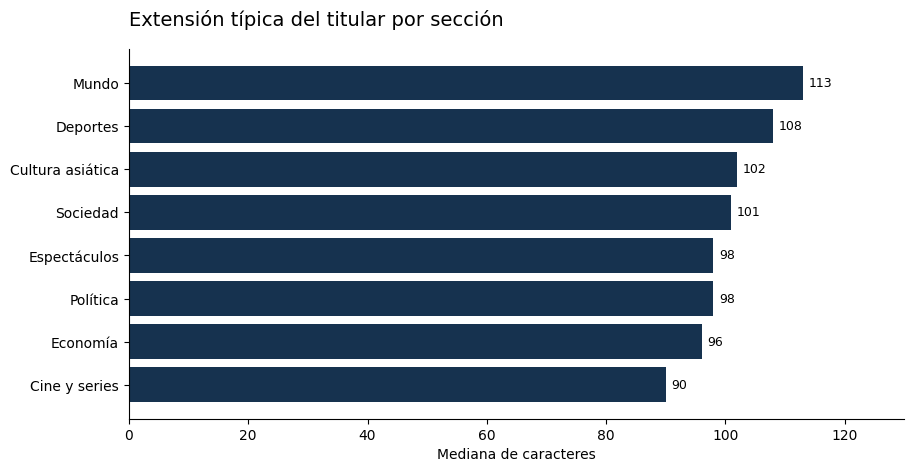

In [7]:
principales=grupo.head(8).index.tolist()
datos=df[df.seccion.isin(principales)]
posiciones=datos.groupby('seccion').longitud_titulo.median().sort_values()
plt.figure(figsize=(10,4.8));ax=plt.gca();b=ax.barh(posiciones.index,posiciones.values,color=AZUL)
ax.bar_label(b,fmt='%.0f',padding=4,fontsize=9);ax.set_xlim(0,posiciones.max()*1.15);ax.set_xlabel('Mediana de caracteres')
ax.set_title('Extensión típica del titular por sección',loc='left',pad=17)
guardar('05_longitud_por_seccion.png')

## 6. Relación entre autores y secciones

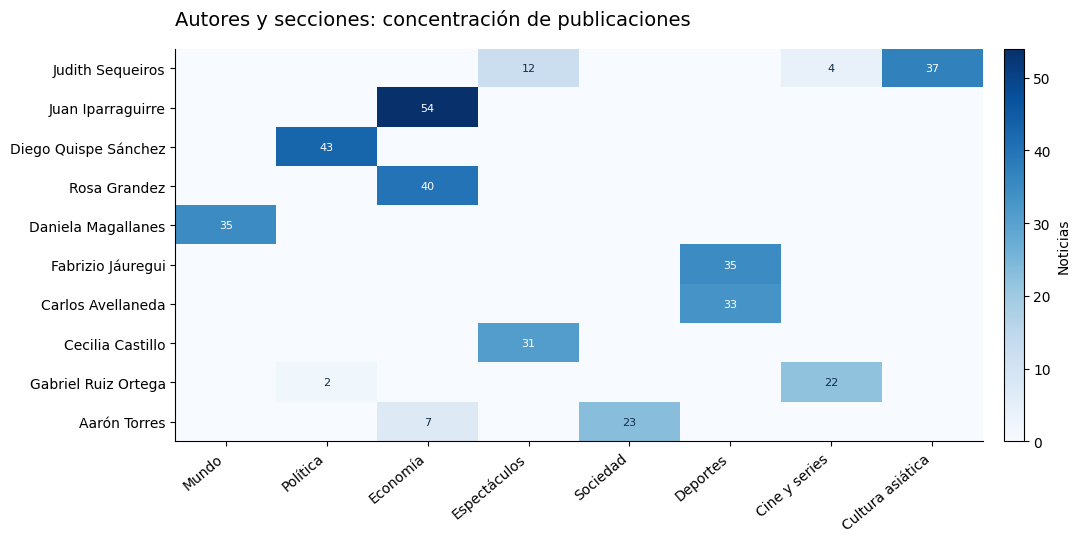

In [8]:
autores=df.autor.value_counts().head(10).index.tolist()
matriz=pd.crosstab(df.autor,df.seccion).reindex(index=autores,columns=principales,fill_value=0)
fig,ax=plt.subplots(figsize=(11,5.1));im=ax.imshow(matriz.values,cmap='Blues',aspect='auto')
ax.set_xticks(np.arange(len(principales)),labels=principales,rotation=40,ha='right')
ax.set_yticks(np.arange(len(autores)),labels=autores)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        x=int(matriz.iloc[i,j]);ax.text(j,i,str(x) if x else '',ha='center',va='center',fontsize=8,color='white' if x>matriz.values.max()*.54 else '#122c44')
c=fig.colorbar(im,ax=ax,fraction=.028,pad=.025);c.set_label('Noticias')
ax.set_title('Autores y secciones: concentración de publicaciones',loc='left',pad=17)
guardar('06_autores_secciones.png')

## 7. Etiquetas temáticas más frecuentes

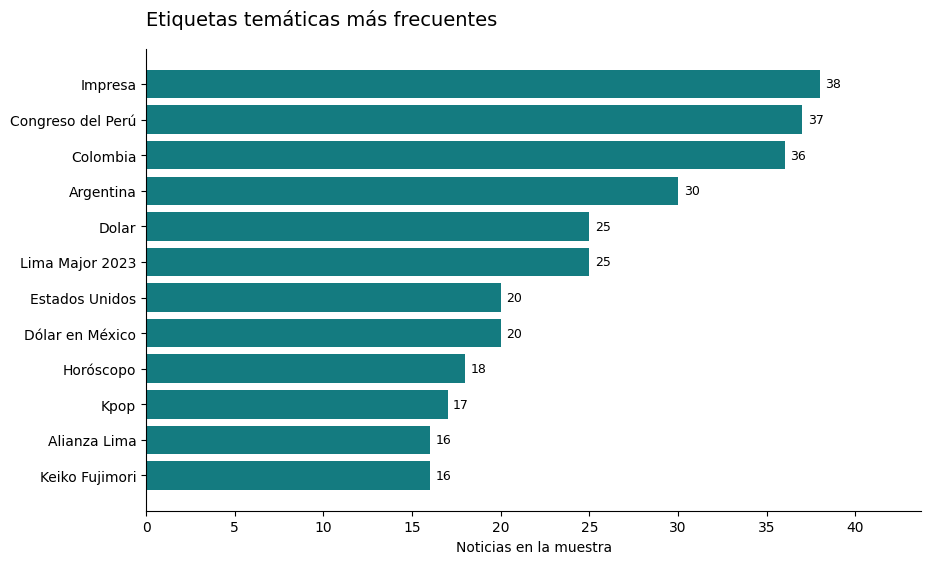

In [9]:
tags=df.tag.value_counts()
top=tags.head(12).sort_values()
plt.figure(figsize=(10,6));ax=plt.gca();bars=ax.barh(top.index,top.values,color=TURQUESA);ax.bar_label(bars,padding=4,fontsize=9)
ax.set_xlim(0,top.max()*1.15);ax.set_xlabel('Noticias en la muestra');ax.set_title('Etiquetas temáticas más frecuentes',loc='left',pad=17)
guardar('07_etiquetas.png')

## 8. Día de la semana registrado

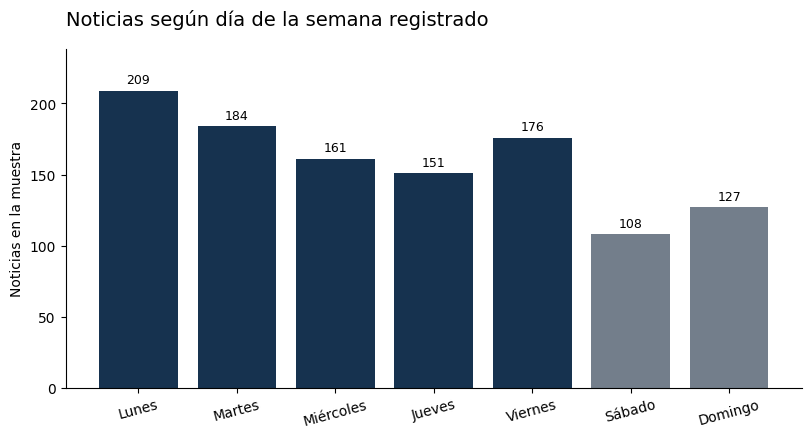

In [10]:
orden=['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo']
dias=df.dia_semana.value_counts().reindex(orden,fill_value=0)
plt.figure(figsize=(9.5,4.4));ax=plt.gca();bars=ax.bar(dias.index,dias.values,color=[AZUL]*5+[GRIS]*2)
ax.bar_label(bars,padding=3,fontsize=9);ax.set_ylabel('Noticias en la muestra');ax.set_ylim(0,dias.max()*1.14)
ax.set_title('Noticias según día de la semana registrado',loc='left',pad=17);ax.tick_params(axis='x',rotation=15)
guardar('08_dias_semana.png')

## Tablas de apoyo

In [11]:
df.groupby('seccion').agg(noticias=('url','size'),mediana_titulo=('longitud_titulo','median'),autores=('autor','nunique')).sort_values('noticias',ascending=False).head(12)

,noticias,mediana_titulo,autores
seccion,,,
Mundo,163,113.0,22
Política,157,98.0,25
Economía,133,96.0,10
Espectáculos,120,98.0,25
Sociedad,99,101.0,17
Deportes,90,108.0,11
Cine y series,62,90.0,8
Cultura asiática,57,102.0,6
Videojuegos,49,91.0,7


In [12]:
df.groupby('franja_horaria',sort=False).agg(noticias=('url','size'),mediana_titulo=('longitud_titulo','median')).sort_values('noticias',ascending=False)

,noticias,mediana_titulo
franja_horaria,,
Tarde (12-17),448,102.5
Mañana (06-11),316,101.0
Noche (18-23),266,105.0
Madrugada (00-05),86,106.0


In [13]:
df.groupby('seccion').agg(noticias=('url','size'),titulares_con_cifras=('contiene_cifra','mean'),titulares_con_interrogacion=('contiene_pregunta','mean')).sort_values('noticias',ascending=False).head(12)

,noticias,titulares_con_cifras,titulares_con_interrogacion
seccion,,,
Mundo,163,0.460123,0.030675
Política,157,0.235669,0.050955
Economía,133,0.706767,0.330827
Espectáculos,120,0.150000,0.150000
Sociedad,99,0.535354,0.070707
Deportes,90,0.611111,0.011111
Cine y series,62,0.354839,0.161290
Cultura asiática,57,0.561404,0.087719
Videojuegos,49,0.816327,0.326531


## Interpretación y límites

Las diferencias entre secciones, autores, etiquetas y tipos de titular muestran la composición de esta colección. La fecha indicada en una URL no se equipara de forma automática con la fecha de publicación. Los patrones por día u hora no representan una serie temporal exhaustiva de la producción del medio.